Build a conditional agent that performs addition or subtraction based on given operator

In [16]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [17]:
class AgentState(TypedDict):
    number1: int
    operator: str
    number2: int
    result: int

In [18]:
def adder(state: AgentState) -> AgentState:
    """this node adds two numbers"""

    state['result'] = state['number1'] + state['number2']

    return state

def subtractor(state: AgentState) -> AgentState:
    """this node subtracts two numbers"""

    state['result'] = state['number1'] - state['number2']

    return state

def decide_condition(state: AgentState) -> AgentState:
    """this node decides which operation to run"""

    if state['operator'] == '+':
        return "addition_operation"
    elif state['operator'] == '-':
        return "subtraction_operation"

In [19]:
graph = StateGraph(AgentState)

graph.add_node('adder', action=adder)
graph.add_node('subtractor', action=subtractor)
graph.add_node('router', lambda state: state)

graph.add_edge(START, 'router')

graph.add_conditional_edges(
    'router',
    decide_condition,
    {
        'addition_operation': 'adder',
        'subtraction_operation': 'subtractor'
    }
)

graph.add_edge('adder', END)
graph.add_edge('subtractor', END)

app = graph.compile()

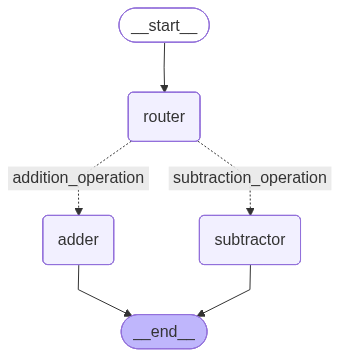

In [20]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [21]:
initial_state1 = AgentState(number1=2, operator='+', number2=3)
print(app.invoke(initial_state1))

{'number1': 2, 'operator': '+', 'number2': 3, 'result': 5}


In [22]:
initial_state2 = AgentState(number1=24, operator='-', number2=20)
print(app.invoke(initial_state2))

{'number1': 24, 'operator': '-', 'number2': 20, 'result': 4}
